In [28]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage,HumanMessage
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

In [15]:
load_dotenv()

True

In [16]:
generator_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")
evaluator_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")
optimizer_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [17]:
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")

In [18]:
str_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [ ]:
class TweetState(TypedDict):
    
    topic : str
    tweet: str
    evaluation : Literal['approved','need_iprovement']
    feedback: str
    iteration:int
    max_iteration: int
    
    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]
        

In [29]:
def generate(state: TweetState):
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]
    
    response = generator_llm.invoke(messages).content
    
    return {'tweet':response ,'tweet_history':[response] }
    

In [31]:
def evaluation(state: TweetState):
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people retweet or share it?  
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]
    
    response = str_evaluator_llm.invoke(messages)
    
    return {
        'evaluation':response.evaluation,
        'feedback':response.feedback,
        'feedback_history':response.feedback
    } 

In [32]:
def optimize(state: TweetState):
    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]
    
    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1
    
    return {'tweet':response,
            'iteration':iteration,
            'tweet_history':[response]
            }
    

In [33]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [24]:
graph = StateGraph(TweetState)

graph.add_node('generate',generate)
graph.add_node('evaluation',evaluation)
graph.add_node('optimize',optimize)


graph.add_edge(START,'generate')
graph.add_edge('generate','evaluation')
graph.add_conditional_edges('evaluation',route_evaluation,{'approved':END,'needs_improvement':'optimize'})

graph.add_edge('optimize','evaluation')

workflow = graph.compile()

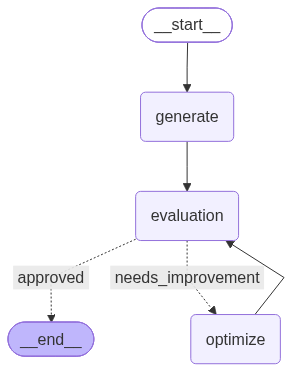

In [25]:
workflow

In [26]:

initial_state = {
    "topic": "Indian Railways",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

In [27]:
result

{'topic': 'Indian Railways',
 'tweet': "My train is 3 hours late. My parents said they'd wait. I guess they also factored in the 2 hours for *my* arrival at the station. It's a whole system. #IndianRailways #IndianStandardTime",
 'evaluation': 'approved',
 'feedback': 'This tweet is well-formatted, concise, and highly relatable, particularly for its target audience, ensuring strong virality potential. The humor stems from a familiar cultural observation, elevated by the self-deprecating twist and the punchy line, "It\'s a whole system." While the core premise isn\'t entirely novel, the execution is sharp and effective, making it genuinely chuckle-worthy without resorting to a traditional setup-punchline structure or exceeding character limits. The hashtags are perfectly chosen to maximize reach and engagement.',
 'iteration': 1,
 'max_iteration': 5}